--- Performance Assessment Results ---
Analysis based on the first 60 seconds of data.

--- Metric 1: Accuracy (Offset) ---
Ground Truth OD:   0.9800
Mean Measured OD:  1.0157
Accuracy Offset:   +0.0357 OD

--- Metric 2: Precision (Noise) ---
Std. Deviation (Noise): 0.076159 OD
This implies a 95% confidence interval of approx. +/- 0.1523 OD

--- Metric 3: Stability (Drift) ---
Drift Rate (Slope): +0.00013165 OD/second
Projected drift over 10 min: +0.0790 OD

Generated plot: 'performance_plot.png'


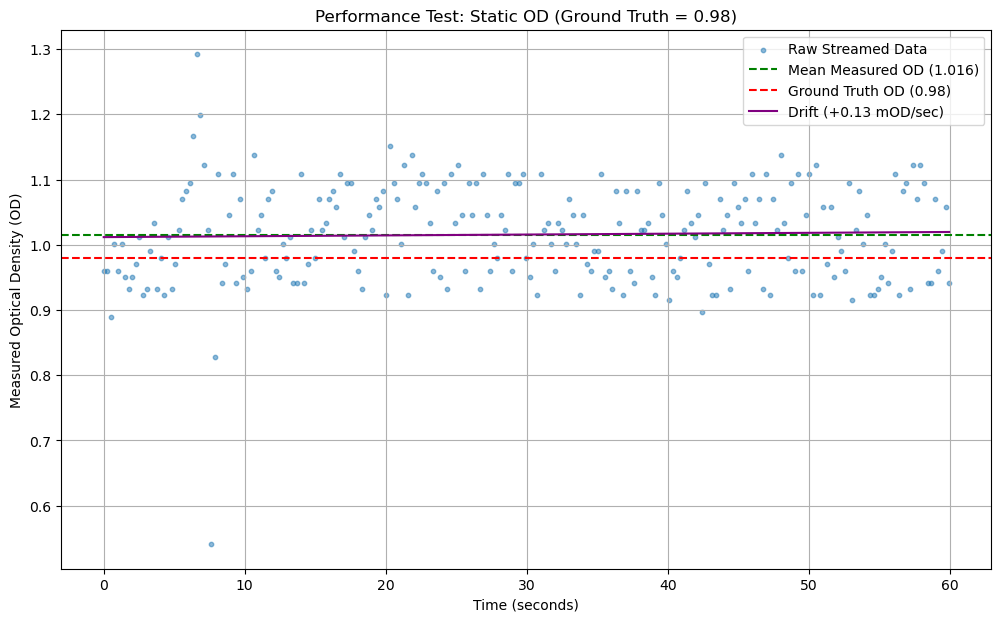

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

# --- Configuration ---
FILENAME = 'od_stream_data_20251112_115938.csv'
GROUND_TRUTH_OD = 0.98
CUT_DURATION_SECONDS = 60

def analyze_performance(filename, ground_truth, duration):
    """
    Loads, cuts, and analyzes the OD stream data to quantify
    accuracy, precision (noise), and stability (drift).
    """
    
    # --- 1. Load and Prepare Data ---
    try:
        df = pd.read_csv(filename)
    except FileNotFoundError:
        print(f"Error: File '{filename}' not found.")
        return

    df['time'] = pd.to_datetime(df['time'])
    df = df.sort_values(by='time')
    
    start_time = df['time'].iloc[0]
    df['elapsed_seconds'] = (df['time'] - start_time).dt.total_seconds()
    
    # --- 2. Cut the 60-second Section ---
    df_cut = df[df['elapsed_seconds'] <= duration].copy()
    
    if df_cut.empty:
        print(f"Error: No data found within the first {duration} seconds.")
        return

    # --- 3. Perform Analysis ---
    
    # Metric 1: Accuracy (Offset)
    mean_od = df_cut['od'].mean()
    accuracy_offset = mean_od - ground_truth
    
    # Metric 2: Precision (Noise)
    noise_std_dev = df_cut['od'].std()
    
    # Metric 3: Stability (Drift)
    # Fit: od = slope * elapsed_seconds + intercept
    fit = linregress(df_cut['elapsed_seconds'], df_cut['od'])
    drift_slope = fit.slope
    
    # --- 4. Print Results for Report ---
    print("--- Performance Assessment Results ---")
    print(f"Analysis based on the first {duration} seconds of data.")
    
    print("\n--- Metric 1: Accuracy (Offset) ---")
    print(f"Ground Truth OD:   {ground_truth:.4f}")
    print(f"Mean Measured OD:  {mean_od:.4f}")
    print(f"Accuracy Offset:   {accuracy_offset:+.4f} OD")
    
    print("\n--- Metric 2: Precision (Noise) ---")
    print(f"Std. Deviation (Noise): {noise_std_dev:.6f} OD")
    print(f"This implies a 95% confidence interval of approx. +/- {2*noise_std_dev:.4f} OD")

    print("\n--- Metric 3: Stability (Drift) ---")
    print(f"Drift Rate (Slope): {drift_slope:+.8f} OD/second")
    print(f"Projected drift over 10 min: {drift_slope * 600:+.4f} OD")

    # --- 5. Generate Plot ---
    plt.figure(figsize=(12, 7))
    plt.scatter(df_cut['elapsed_seconds'], df_cut['od'], alpha=0.5, s=10, label='Raw Streamed Data')
    
    # Plot mean, truth, and drift
    plt.axhline(y=mean_od, color='green', linestyle='--', label=f'Mean Measured OD ({mean_od:.3f})')
    plt.axhline(y=GROUND_TRUTH_OD, color='red', linestyle='--', label=f'Ground Truth OD ({GROUND_TRUTH_OD})')
    
    # Plot drift line
    drift_line = fit.intercept + fit.slope * df_cut['elapsed_seconds']
    plt.plot(df_cut['elapsed_seconds'], drift_line, color='purple', 
             label=f'Drift ({drift_slope*1000:+.2f} mOD/sec)')
    
    plt.title(f'Performance Test: Static OD (Ground Truth = {GROUND_TRUTH_OD})')
    plt.xlabel('Time (seconds)')
    plt.ylabel('Measured Optical Density (OD)')
    plt.legend()
    plt.grid(True)
    plot_filename = 'performance_plot.png'
    plt.savefig(plot_filename)
    print(f"\nGenerated plot: '{plot_filename}'")

# --- Run the Analysis ---
if __name__ == "__main__":
    analyze_performance(FILENAME, GROUND_TRUTH_OD, CUT_DURATION_SECONDS)